# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.

### NASA Asteroids, predicting hazardous (yes / no)

**What you are figuring out:** from an asteroid's size and orbital measurements, can you
predict whether NASA flags it as hazardous? This is the cleanest Decision Tree versus
Naive Bayes comparison of the three.

- **Exploration:** check the class balance first. Only about 16% are hazardous, so a model that always guesses "not hazardous" is already about 84% accurate. That is the baseline you must beat, and it is why accuracy alone will mislead you.
- **Preprocessing:** drop columns that carry no signal, such as `id` and `name`. The features are on very different scales (diameter versus orbital period), so apply feature scaling. This matters a lot for Naive Bayes.
- **Build models:** run both a Decision Tree and Naive Bayes on the same task and compare them directly.
- **Evaluate:** because the classes are imbalanced, report precision and recall for the "hazardous" class, not just accuracy. Recall matters most here: a missed hazardous asteroid is the costly error.

### Hotel Booking, predicting cancellation or hotel type

**What you are figuring out:** can booking details predict whether a reservation will be
cancelled, or whether it is a city versus resort hotel? This one is encoding-heavy.

- **Exploration:** check the cancellation rate (the classes may be imbalanced) and scan which columns are text versus numeric.
- **Preprocessing:** many columns are categorical and need encoding (`get_dummies` or `LabelEncoder`). Date columns are not useful raw; pull out useful pieces like the month. Watch for NULLs that are actually meaningful: a missing travel-agent value usually means "no agent," not bad data, so do not blindly drop those rows.
- **Build models:** Decision Tree for one task, Naive Bayes for the other.
- **Evaluate:** if cancellations are the minority class, look at precision and recall for cancellations, not just overall accuracy.

In [79]:
# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [80]:
# GIVEN: load the dataset. Change this path to your group's file when you have it.
df = pd.read_csv("nasa.csv")

# Set this to the name of the column you are predicting.
target = "Hazardous"

df.head()
df.shape

(4687, 40)

In [81]:
## TODO: explore the data
# Hint: df.shape, df.info(), and df[target].value_counts()
# Also try df.describe() for the numeric columns.
#df.shape
#df.info()
df[target].value_counts()
#df.describe()




Hazardous
False    3932
True      755
Name: count, dtype: int64

## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [82]:
# TODO: drop unhelpful columns and handle missing values
# Hint: start from a copy -> data = df.drop(columns=["applicant_id"]).copy()
# Hint for missing values, loop over columns:
#   if pd.api.types.is_numeric_dtype(data[col]): fill with data[col].median()
#   else: fill with data[col].mode()[0]
data = df.drop(columns=["Neo Reference ID"]).copy()

for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].median())
    else:
        data[col] = data[col].fillna(data[col].mode()[0])

print("Missing Values remaing:", int(data.isna().sum().sum()))





Missing Values remaing: 0


In [83]:
# TODO: build X (features) and y (target), then encode the categorical columns
y = data[target]
features = data.drop(columns=[target])
X = pd.get_dummies(features, drop_first=True)
print(list(X.columns))
X.head()





['Name', 'Absolute Magnitude', 'Est Dia in KM(min)', 'Est Dia in KM(max)', 'Est Dia in M(min)', 'Est Dia in M(max)', 'Est Dia in Miles(min)', 'Est Dia in Miles(max)', 'Est Dia in Feet(min)', 'Est Dia in Feet(max)', 'Epoch Date Close Approach', 'Relative Velocity km per sec', 'Relative Velocity km per hr', 'Miles per hour', 'Miss Dist.(Astronomical)', 'Miss Dist.(lunar)', 'Miss Dist.(kilometers)', 'Miss Dist.(miles)', 'Orbit ID', 'Orbit Uncertainity', 'Minimum Orbit Intersection', 'Jupiter Tisserand Invariant', 'Epoch Osculation', 'Eccentricity', 'Semi Major Axis', 'Inclination', 'Asc Node Longitude', 'Orbital Period', 'Perihelion Distance', 'Perihelion Arg', 'Aphelion Dist', 'Perihelion Time', 'Mean Anomaly', 'Mean Motion', 'Close Approach Date_1995-01-08', 'Close Approach Date_1995-01-15', 'Close Approach Date_1995-01-22', 'Close Approach Date_1995-02-08', 'Close Approach Date_1995-02-15', 'Close Approach Date_1995-02-22', 'Close Approach Date_1995-03-08', 'Close Approach Date_1995-03

,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),Est Dia in Feet(max),...,Orbit Determination Date_2017-09-27 06:52:18,Orbit Determination Date_2017-09-27 06:52:20,Orbit Determination Date_2017-09-27 06:52:31,Orbit Determination Date_2017-09-27 15:42:08,Orbit Determination Date_2017-09-28 06:48:13,Orbit Determination Date_2017-09-28 06:48:14,Orbit Determination Date_2017-09-28 06:48:20,Orbit Determination Date_2017-09-28 06:49:17,Orbit Determination Date_2017-09-28 06:49:19,Orbit Determination Date_2017-09-28 06:49:30
0,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,933.308089,...,False,False,False,False,False,False,False,False,False,False
1,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,1071.581063,...,False,False,False,False,False,False,False,False,False,False
2,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,1698.341531,...,False,False,False,False,False,False,False,False,False,False
3,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,64.569144,...,False,False,False,False,False,False,False,False,False,False
4,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,933.308089,...,False,False,False,False,False,False,False,False,False,False


In [84]:
# TODO: split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)
print("Training rows:", X_train.shape[0], "Test rows:", X_test.shape[0])



Training rows: 3515 Test rows: 1172


## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

Decision tree accuracy: 0.994
Decision tree - confusion matrix


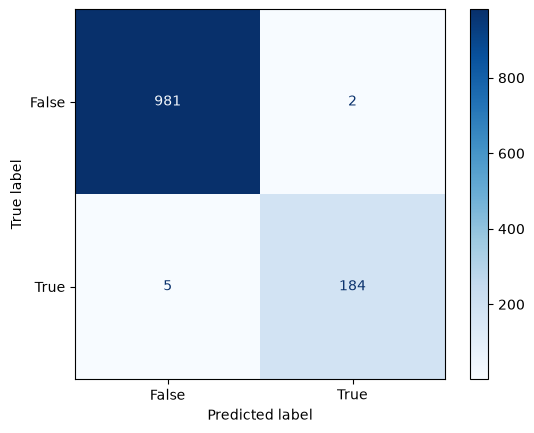

              precision    recall  f1-score   support

       False       0.99      1.00      1.00       983
        True       0.99      0.97      0.98       189

    accuracy                           0.99      1172
   macro avg       0.99      0.99      0.99      1172
weighted avg       0.99      0.99      0.99      1172



In [85]:
# TODO: train a Decision Tree
dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train, y_train)
dt_pred = dtree.predict(X_test)

print("Decision tree accuracy:", round(accuracy_score(y_test, dt_pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues")
print("Decision tree - confusion matrix")
plt.show()
print(classification_report(y_test, dt_pred))




Naive Bayes accuracy: 0.839


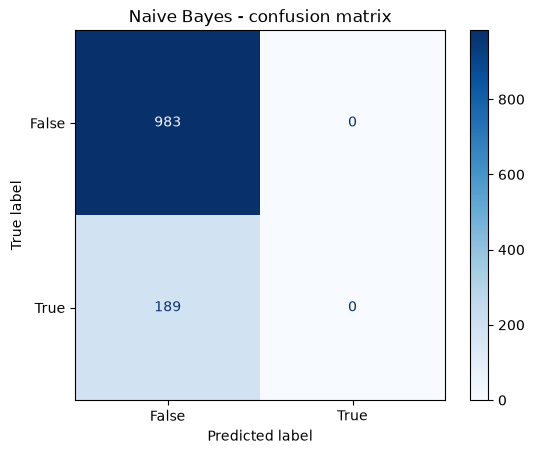

              precision    recall  f1-score   support

       False       0.84      1.00      0.91       983
        True       0.00      0.00      0.00       189

    accuracy                           0.84      1172
   macro avg       0.42      0.50      0.46      1172
weighted avg       0.70      0.84      0.77      1172



c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

In [86]:
# TODO: train a Naive Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("Naive Bayes accuracy:", round(accuracy_score(y_test, nb_pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues")
plt.title("Naive Bayes - confusion matrix")
plt.show()
print(classification_report(y_test, nb_pred))


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

0.9940273037542662


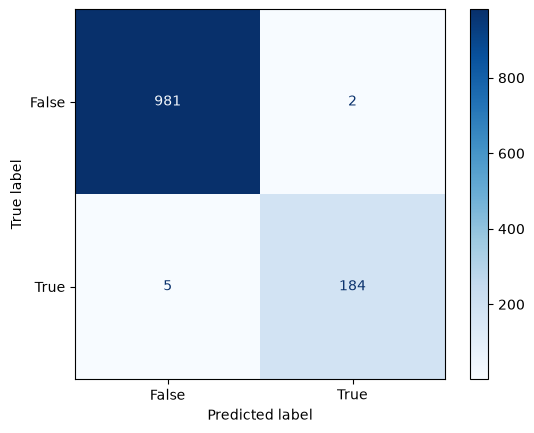

              precision    recall  f1-score   support

       False       0.99      1.00      1.00       983
        True       0.99      0.97      0.98       189

    accuracy                           0.99      1172
   macro avg       0.99      0.99      0.99      1172
weighted avg       0.99      0.99      0.99      1172



In [87]:
# TODO: evaluate the Decision Tree
dt_pred = dtree.predict(X_test)
print(accuracy_score(y_test, dt_pred))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues"); plt.show()
print(classification_report(y_test, dt_pred))




0.8387372013651877


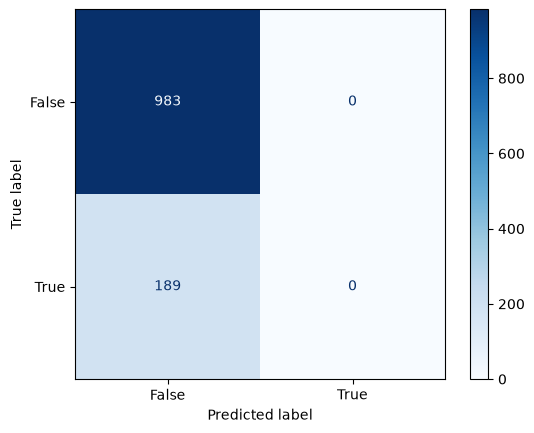

              precision    recall  f1-score   support

       False       0.84      1.00      0.91       983
        True       0.00      0.00      0.00       189

    accuracy                           0.84      1172
   macro avg       0.42      0.50      0.46      1172
weighted avg       0.70      0.84      0.77      1172



c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ellie\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

In [88]:
# TODO: evaluate the Naive Bayes model (same steps as above)

nb_pred = nb_model.predict(X_test)
print(accuracy_score(y_test, nb_pred))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues"); plt.show()
print(classification_report(y_test, nb_pred))


Baseline (always No)    0.839
Decision tree           0.994
Naive Bayes             0.839
dtype: float64


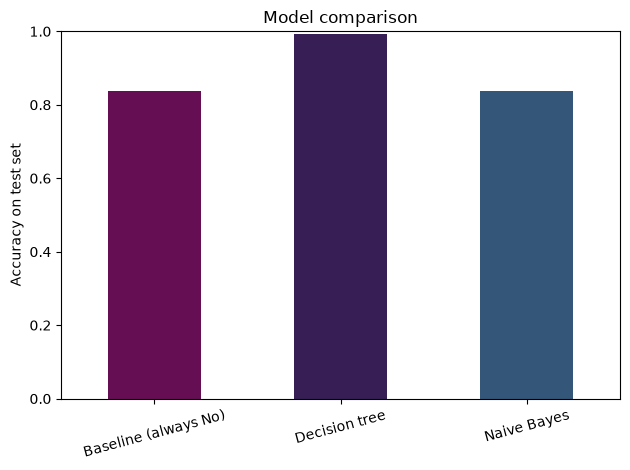

In [89]:
# TODO: compare the two models' accuracy against a baseline
baseline = y_test.value_counts(normalize=True).max()
# A simple bar chart makes the comparison clear.
scores = pd.Series({"Baseline (always No)": baseline,
                    "Decision tree": accuracy_score(y_test, dt_pred),
                    "Naive Bayes": accuracy_score(y_test, nb_pred)})
print(scores.round(3))

scores.plot(kind="bar", color=["#650E54", "#371F55", "#345678"])
plt.ylabel("Accuracy on test set")
plt.title("Model comparison")
plt.ylim(0, 1)
plt.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()



## Step 5 - Findings

Write your answers here as you work.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   *Your answer:* We had to drop the id column because it was not useful, as well as fill in missing values with the median or mean to make it more accurate. We encoded the target as well so that the model can be trained on our data.

2. **Data used** - which features did you select as predictors, and why those?

   *Your answer:* We selected the hazardous column as our predictors, because that was our target value.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   *Your answer:* The analysis revealed that very few of the astroids are actually hazardous.

4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the
   strengths and shortcomings of each one here?

   *Your answer:* The decision tree performed better on our task, when it predicted how many were hazardous it had a 99% accuracy for both true and false columns. The Naive Bayes said all of them were false, when that is not the reality.  

   Decision trees can be super simple to look at, and are great at handling conditions, like if someone is a student it is likely they will buy a computer. However, when handling a lot of decisions they can get caught up in tiny details rather than finding the pattern

   Naive Bayes are really scalable and has a low data requirement. However, it assumes that all input features are completely independent. It also predicted the True column to just be 0 flat out.

5. **Challenges** - What was difficult, and how did you handle it?

   *Your answer:* Our Kernel was crashing which was really difficult. However, it was fixed relatively fast by updating both the Kernel and the extension things. 

## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository